# Customer Retention & Repeat Purchase Analysis – E-commerce Beauty Store

**Context:** an online beauty store has many customers who buy once and never come back. This project measures how many customers return, finds where they drop off on the way to a repeat purchase, groups customers for targeted care, and proposes a way to test a repurchase offer.

**Analysis questions**
1. In which quarters do most new customers arrive, and do they come back? (quarterly cohort retention)
2. How do Corporate and Consumer customers differ in their likelihood to return?
3. How many customers move from the 1st order to the 2nd, 3rd and 4th, and how long does the 2nd order take? (repeat-purchase funnel)
4. Which groups should customers be divided into, and which groups drive revenue? (RFM)
5. How do repeat buyers differ from one-time buyers? (income, profit per order, product categories)
6. What should the store do, and how can it be tested? (recommendations and A/B test design)

**Data:** a sample e-commerce dataset of a beauty store with 4 tables: `EcomSales` (sales lines), `Customer`, `Product`, `Region`.

**Tools:** Python (pandas, numpy, matplotlib, seaborn, statsmodels), Jupyter.

**Contents**
- I. Data preparation and cleaning
- II. Customer and order overview
- III. Cohort analysis (by quarter, by Segment)
- IV. Repeat-purchase funnel
- V. Customer segmentation with RFM
- VI. Profile of repeat buyers
- VII. A/B test design
- VIII. Conclusions, recommendations and data limitations

# I. Data preparation and cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', '{:.2f}'.format)

In [2]:
customers = pd.read_csv('Customer.csv')
ecomsales = pd.read_csv('EcomSales.csv')
product   = pd.read_csv('Product.csv')
region    = pd.read_csv('Region.csv')

for t in (customers, ecomsales, product, region):
    display(t.head(2))

,CustomerID,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,EducationLevel,Occupation,HomeOwner
0,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,Y
1,BD-116051,Eugene,Torres,6/16/1985,S,M,eugene10@hotmail.com,60000,Bachelors,Professional,N


,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.00,208.00
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.00,10.00


,ProductCode,Product,Category,Subcategory
0,P000001,Soap & Glory Endless Glove Moisturizing Hand C...,Body care,"bath oils, bubbles and soaks"
1,P000002,Pantene Pro-V Truly Relaxed Hair Lightweight C...,Body care,"bath oils, bubbles and soaks"


,RegionCode,City,State,Country,Countrylatitude,Countrylongitude,Region,Market
0,R0001,Jalalabad,Nangarhar,Afghanistan,33.94,67.71,Southern Asia,Asia Pacific
1,R0002,Herat,Hirat,Afghanistan,33.94,67.71,Southern Asia,Asia Pacific


**Observations:**
- `EcomSales`: 1 row = 1 product in 1 order (an order can have several rows); it contains Sales, Discount, Profit and the customer segment (Segment).
- `Customer`, `Product` and `Region` are reference tables, joined to `EcomSales` through `CustomerID`, `ProductCode` and `RegionCode`.
- The first 2 rows already show codes with an unusual format (`RRR0001`, `PPP000002`), so the join keys need to be checked.

## 1.1. Data checks

In [3]:
def check_dataframe(df):
    """Check structure, missing values, duplicate rows and descriptive statistics of a table."""
    print("=" * 50, "\n1. DATAFRAME INFO\n" + "=" * 50)
    df.info()
    print("\n" + "=" * 50, "\n2. MISSING VALUES\n" + "=" * 50)
    print(df.isna().sum())
    print("\n" + "=" * 50, "\n3. DUPLICATE ROWS\n" + "=" * 50)
    print(f"Number of duplicate rows: {df.duplicated().sum()}")
    print("\n" + "=" * 50, "\n4. DESCRIPTIVE STATISTICS\n" + "=" * 50)
    print(df.describe().T)

In [4]:
check_dataframe(customers)

1. DATAFRAME INFO
<class 'pandas.DataFrame'>
RangeIndex: 17415 entries, 0 to 17414
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      17415 non-null  str  
 1   FirstName       17415 non-null  str  
 2   LastName        17415 non-null  str  
 3   BirthDate       17415 non-null  str  
 4   MaritalStatus   17415 non-null  str  
 5   Gender          17291 non-null  str  
 6   EmailAddress    17415 non-null  str  
 7   AnnualIncome    17415 non-null  int64
 8   EducationLevel  17415 non-null  str  
 9   Occupation      17415 non-null  str  
 10  HomeOwner       17415 non-null  str  
dtypes: int64(1), str(10)
memory usage: 1.5 MB

2. MISSING VALUES
CustomerID          0
FirstName           0
LastName            0
BirthDate           0
MaritalStatus       0
Gender            124
EmailAddress        0
AnnualIncome        0
EducationLevel      0
Occupation          0
HomeOwner           0
dtype: int64

3. 

In [5]:
check_dataframe(ecomsales)

1. DATAFRAME INFO
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   RowID        51290 non-null  int64  
 1   OrderID      51290 non-null  str    
 2   OrderDate    51290 non-null  str    
 3   CustomerID   51290 non-null  str    
 4   Segment      51290 non-null  str    
 5   RegionCode   51290 non-null  str    
 6   ProductCode  51290 non-null  str    
 7   Quantity     51290 non-null  int64  
 8   Sales        51290 non-null  int64  
 9   Discount     51290 non-null  float64
 10  Profit       51290 non-null  float64
dtypes: float64(2), int64(3), str(6)
memory usage: 4.3 MB

2. MISSING VALUES
RowID          0
OrderID        0
OrderDate      0
CustomerID     0
Segment        0
RegionCode     0
ProductCode    0
Quantity       0
Sales          0
Discount       0
Profit         0
dtype: int64

3. DUPLICATE ROWS
Number of duplicate rows: 0

4. DESCRIPTIV

In [6]:
check_dataframe(product)

1. DATAFRAME INFO
<class 'pandas.DataFrame'>
RangeIndex: 28356 entries, 0 to 28355
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ProductCode  28356 non-null  str  
 1   Product      28356 non-null  str  
 2   Category     28356 non-null  str  
 3   Subcategory  28356 non-null  str  
dtypes: str(4)
memory usage: 886.3 KB

2. MISSING VALUES
ProductCode    0
Product        0
Category       0
Subcategory    0
dtype: int64

3. DUPLICATE ROWS
Number of duplicate rows: 0

4. DESCRIPTIVE STATISTICS
             count unique                                         top   freq
ProductCode  28356  28356                                     P000001      1
Product      28356   3577  NARS Single Eyeshadow Persia Matte Paprika     17
Category     28356      5                                   Body care  11548
Subcategory  28356     17                          Nail care products   2386


In [7]:
check_dataframe(region)

1. DATAFRAME INFO
<class 'pandas.DataFrame'>
RangeIndex: 3828 entries, 0 to 3827
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   RegionCode        3828 non-null   str    
 1   City              3828 non-null   str    
 2   State             3828 non-null   str    
 3   Country           3828 non-null   str    
 4   Countrylatitude   3828 non-null   float64
 5   Countrylongitude  3828 non-null   float64
 6   Region            3828 non-null   str    
 7   Market            3828 non-null   str    
dtypes: float64(2), str(6)
memory usage: 239.4 KB

2. MISSING VALUES
RegionCode          0
City                0
State               0
Country             0
Countrylatitude     0
Countrylongitude    0
Region              0
Market              0
dtype: int64

3. DUPLICATE ROWS
Number of duplicate rows: 0

4. DESCRIPTIVE STATISTICS
                   count  mean   std     min    25%   50%   75%    max
Countrylatitud

**Data check observations:**
- **Missing values:** `Customer.Gender` is missing in 124 rows. It is kept as is because Gender is not used in the analysis. The other tables have no missing values.
- **Duplicates:** no duplicate rows in any of the 4 tables.
- **Data types:** `OrderDate` and `BirthDate` are stored as text and are converted to datetime in the next step.
- **Unusual values:** the lowest Profit is -1746.0 (a loss-making order, possibly due to a high discount); it is kept because it is a real transaction. Discount ranges from 0 to 85%.

## 1.2. Standardise join keys, convert dates, join tables

In [8]:
# Standardise keys: strip spaces, uppercase, collapse repeated prefixes (PPP… → P…, RRR… → R…)
def clean_code(s, prefix=''):
    s = s.astype(str).str.strip().str.upper()
    return s.str.replace(rf'^{prefix}+', prefix, regex=True) if prefix else s

for t in (ecomsales, product):   t['ProductCode'] = clean_code(t['ProductCode'], 'P')
for t in (ecomsales, region):    t['RegionCode']  = clean_code(t['RegionCode'], 'R')
for t in (ecomsales, customers): t['CustomerID']  = clean_code(t['CustomerID'])

# Check: every key in ecomsales exists in its reference table
{col: int((~ecomsales[col].isin(ref[col])).sum())
 for col, ref in {'ProductCode': product, 'RegionCode': region, 'CustomerID': customers}.items()}

{'ProductCode': 0, 'RegionCode': 0, 'CustomerID': 0}

**Observations:** some codes have a repeated prefix (e.g. `PPP000002`, `RRR0001`), which prevents a few rows from joining. After standardisation, every key in `EcomSales` matches its reference table.

In [9]:
# Convert dates (month/day/year format)
ecomsales['OrderDate'] = pd.to_datetime(ecomsales['OrderDate'], format='%m/%d/%Y')
customers['BirthDate'] = pd.to_datetime(customers['BirthDate'], format='%m/%d/%Y')

# Join the 4 tables: each sales line with customer, product and region details
df = (ecomsales.merge(customers, on='CustomerID', how='left')
               .merge(product, on='ProductCode', how='left')
               .merge(region, on='RegionCode', how='left'))

print(df.shape)                                  # row count must equal ecomsales
df.isna().sum()[lambda s: s > 0]                 # columns still missing values after the join

(51290, 31)


Gender    362
dtype: int64

In [10]:
# Does each customer belong to only 1 Segment? (if not, a Segment breakdown would double-count customers)
ecomsales.groupby('CustomerID')['Segment'].nunique().value_counts()

Segment
1    17415
Name: count, dtype: int64

**Observations:** after the join there are still 51,290 rows; only `Gender` has missing values (362 rows, not used in the analysis). Each customer belongs to exactly 1 Segment, so Corporate and Consumer can be compared without double-counting customers.

# II. Customer and order overview

An order can contain several product lines, so the data is first aggregated to **order level** (`orders`) and **customer level** (`cust`). Both tables are reused in the following sections.

In [11]:
# Order table: 1 row = 1 order
orders = (ecomsales.groupby(['CustomerID', 'OrderID'], as_index=False)
          .agg(OrderDate=('OrderDate', 'min'), Segment=('Segment', 'first'),
               Sales=('Sales', 'sum'), Profit=('Profit', 'sum'), Discount=('Discount', 'mean'))
          .sort_values(['CustomerID', 'OrderDate', 'OrderID'], ignore_index=True))
orders['order_no'] = orders.groupby('CustomerID').cumcount() + 1       # order sequence number for each customer

# Customer table: 1 row = 1 customer
cust = (orders.groupby('CustomerID')
        .agg(Frequency=('OrderID', 'count'), first_order=('OrderDate', 'min'), last_order=('OrderDate', 'max'),
             Monetary=('Sales', 'sum'), Segment=('Segment', 'first'))
        .reset_index())

# Group by actual number of orders (not equal-width bins, since 89% of customers place only 1–2 orders)
cust['F_score'] = pd.cut(cust['Frequency'], bins=[0, 1, 2, 3, 4, 100],
                         labels=['1 order', '2 orders', '3 orders', '4 orders', '5+ orders'])

pd.Series({'n_rows': f"{len(ecomsales):,}", 'n_orders': f"{len(orders):,}",
           'n_customers': f"{len(cust):,}",
           'first_date': orders['OrderDate'].min().date(), 'last_date': orders['OrderDate'].max().date(),
           'total_sales': f"{orders['Sales'].sum():,.0f}",
           'total_profit': f"{orders['Profit'].sum():,.0f}"}).to_frame('value')

,value
n_rows,"51,290"
n_orders,"25,739"
n_customers,"17,415"
first_date,2020-01-01
last_date,2023-12-31
total_sales,"6,517,674"
total_profit,"1,065,414"


,n_customers,pct
F_score,,
1 order,11979,68.80
2 orders,3467,19.90
3 orders,1311,7.50
4 orders,457,2.60
5+ orders,201,1.20


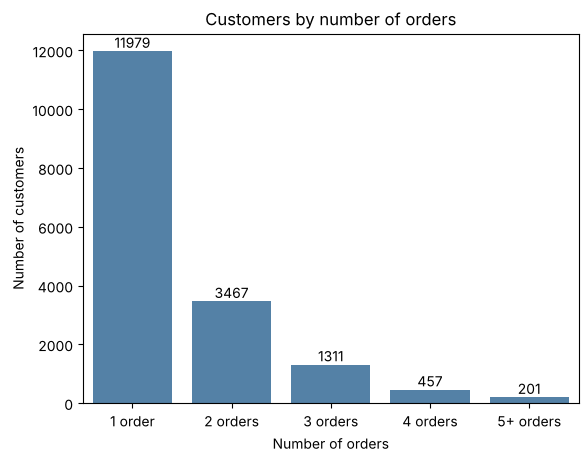

In [12]:
# Distribution of orders per customer
freq_table = (cust['F_score'].value_counts().sort_index().to_frame('n_customers')
              .assign(pct=lambda d: (d['n_customers'] / d['n_customers'].sum() * 100).round(1)))
display(freq_table)

ax = sns.barplot(x=freq_table.index, y=freq_table['n_customers'], color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Customers by number of orders')
plt.xlabel('Number of orders')
plt.ylabel('Number of customers')
plt.show()

**OBSERVATIONS:**
- There are 17,415 customers; 69% (11,979 customers) placed only 1 order, and 89% placed 1–2 orders.
- Only 201 customers (about 1%) placed 5 or more orders; about 11% placed 3 or more.

**INSIGHT:**
- The store's biggest problem is that customers do not come back after their first purchase. The following sections measure returns over time (cohort), find where customers drop off (funnel), group customers (RFM) and propose ways to move customers to a second order.

# III. Cohort analysis

- **Cohort** = the quarter of each customer's first purchase.
- **quarter_after** = number of quarters since the first-purchase quarter (0 = first-purchase quarter).
- Value = number of **distinct** customers who bought in that quarter; retention = that number divided by the cohort size.

In [13]:
cohort_df = orders.merge(cust[['CustomerID', 'first_order']], on='CustomerID')
cohort_df['first_quarter'] = cohort_df['first_order'].dt.to_period('Q')
cohort_df['quarter_after'] = ((cohort_df['OrderDate'].dt.year - cohort_df['first_order'].dt.year) * 4 +
                              (cohort_df['OrderDate'].dt.quarter - cohort_df['first_order'].dt.quarter))

cohort_counts = cohort_df.pivot_table(index='first_quarter', columns='quarter_after',
                                      values='CustomerID', aggfunc='nunique')
cohort_size = cohort_counts[0]
retention = cohort_counts.divide(cohort_size, axis=0)
retention.round(3)

quarter_after,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
first_quarter,,,,,,,,,,,,,,,,
2020Q1,1.00,0.04,0.06,0.06,0.04,0.04,0.04,0.06,0.04,0.05,0.06,0.07,0.04,0.08,0.09,0.10
2020Q2,1.00,0.04,0.05,0.03,0.04,0.06,0.07,0.04,0.06,0.06,0.09,0.05,0.07,0.09,0.09,NaN
2020Q3,1.00,0.05,0.03,0.05,0.06,0.07,0.03,0.05,0.08,0.09,0.04,0.06,0.07,0.09,NaN,NaN
2020Q4,1.00,0.04,0.04,0.05,0.08,0.04,0.06,0.07,0.07,0.04,0.08,0.07,0.11,NaN,NaN,NaN
2021Q1,1.00,0.05,0.04,0.07,0.03,0.05,0.07,0.09,0.05,0.06,0.07,0.10,NaN,NaN,NaN,NaN
2021Q2,1.00,0.05,0.07,0.03,0.05,0.06,0.07,0.04,0.06,0.07,0.10,NaN,NaN,NaN,NaN,NaN
2021Q3,1.00,0.05,0.03,0.05,0.06,0.07,0.04,0.07,0.07,0.09,NaN,NaN,NaN,NaN,NaN,NaN
2021Q4,1.00,0.04,0.05,0.06,0.07,0.05,0.06,0.07,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022Q1,1.00,0.04,0.07,0.06,0.04,0.06,0.08,0.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


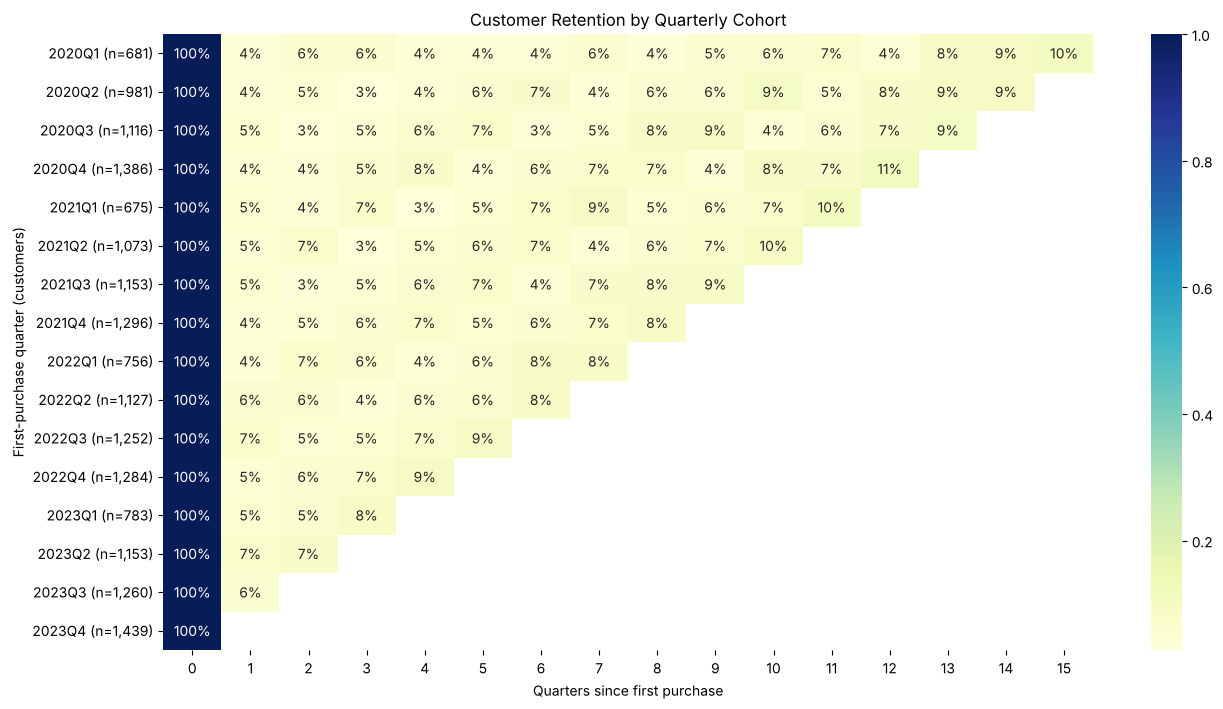

In [14]:
# Retention heatmap; cohort size shown in the y-axis labels
labels = [f'{q} (n={int(n):,})' for q, n in cohort_size.items()]
plt.figure(figsize=(15, 8))
sns.heatmap(retention, annot=True, cmap='YlGnBu', fmt='.0%', yticklabels=labels)
plt.xlabel('Quarters since first purchase')
plt.ylabel('First-purchase quarter (customers)')
plt.title('Customer Retention by Quarterly Cohort')
plt.show()

## 3.1. Quarters that attract customers

**OBSERVATIONS:**
- Q1 of each year has the fewest new customers (e.g. 681 in 2020Q1, 675 in 2021Q1); Q4 has the most (e.g. 1,386 in 2020Q4).
- Retention after 1 quarter is only about 4–6% for most cohorts; later quarters fluctuate around 3–9% and do not decline steadily.
- A possible explanation: Q1 comes right after the year-end shopping season and Lunar New Year, so demand and advertising budgets fall; Q4 has major sales events (11/11, Black Friday), year-end gifting and self-reward spending. This is a hypothesis; the data has no information on promotions or marketing spend to verify it.

**INSIGHT:**
- New customers are concentrated in the middle and end of the year.
- Q1 cohorts retain about as well as other quarters (about 4–6% after 1 quarter), so Q1 brings fewer customers but they are no less likely to return.

**ACTION SUGGESTIONS:**
- Run post-purchase care for Q4's new customers (the largest group, e.g. 1,386 customers in 2020Q4): send a voucher or a repurchase reminder to bring them back in Q1.
- Try launching new products or collections in Q1 to see whether they attract more new customers, instead of assuming Q1 is a weak quarter.
- Re-measure new customers and retention for each quarter before shifting advertising budgets.

## 3.2. Retention: Corporate vs Consumer

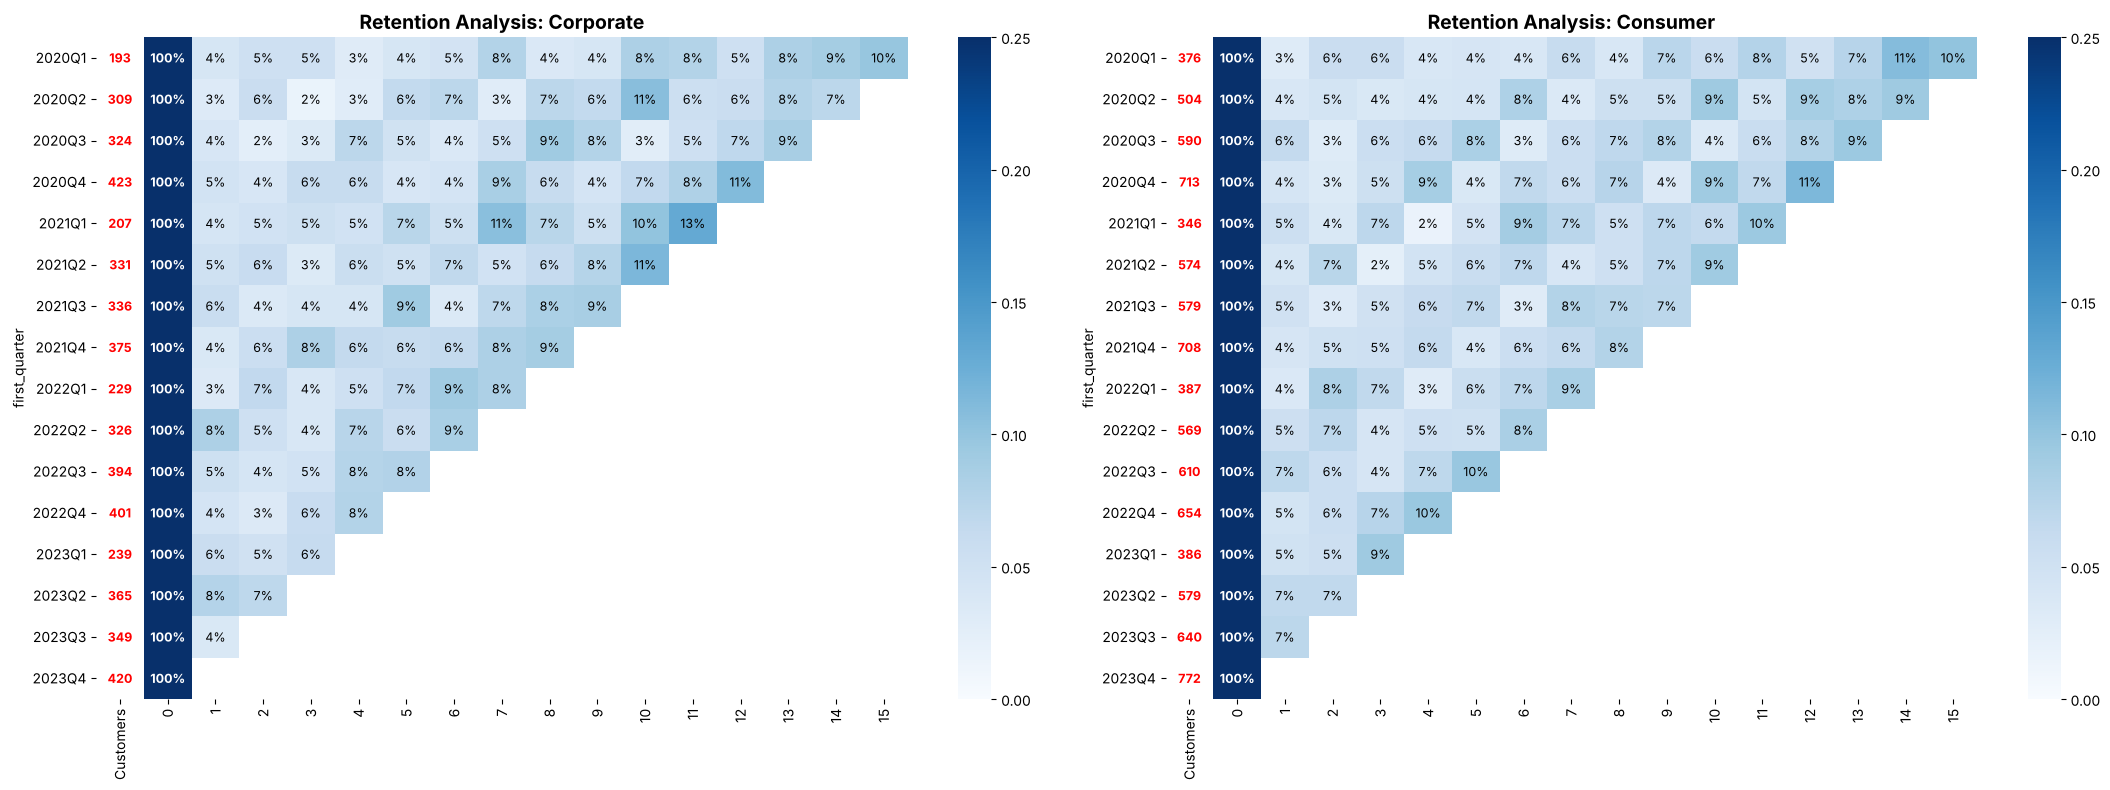

In [15]:
def plot_segment_cohort(ax, df_seg, title):
    """Plot a retention heatmap (first column = cohort size) for one Segment."""
    pivot = df_seg.pivot_table(index='first_quarter', columns='quarter_after', values='CustomerID', aggfunc='nunique')
    size = pivot.iloc[:, 0]
    ret = pivot.divide(size, axis=0)
    table = pd.concat([size.rename('Customers'), ret], axis=1).dropna(axis=1, how='all')

    mask = np.zeros_like(table, dtype=bool)
    mask[:, 0] = True                                        # do not colour the Customers column
    sns.heatmap(table, annot=False, cmap='Blues', ax=ax, mask=mask, vmin=0, vmax=0.25)
    for r in range(table.shape[0]):
        for k in range(table.shape[1]):
            val = table.iloc[r, k]
            if pd.notna(val):
                color = 'red' if k == 0 else ('white' if k == 1 else 'black')
                text = f'{int(val)}' if k == 0 else f'{val:.0%}'
                ax.text(k + 0.5, r + 0.5, text, ha='center', va='center', color=color,
                        fontweight='bold' if k <= 1 else 'normal', fontsize=9)
    ax.set_title(f'Retention Analysis: {title}', fontsize=14, fontweight='bold')

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, seg in zip(axes, ['Corporate', 'Consumer']):
    plot_segment_cohort(ax, cohort_df[cohort_df['Segment'] == seg], seg)
plt.tight_layout()
plt.show()

**OBSERVATIONS:** the two segments behave quite similarly.
- Corporate: about 190–420 customers per cohort. The quarterly return rate fluctuates around 3–8% and does not decline over time; in later quarters some cohorts reach 9–13% (e.g. 2021Q1 reaches 13% in quarter 10).
- Consumer: larger cohorts (about 350–770 customers each). The return rate is also around 3–8% and edges up to 10–11% in later quarters, almost the same as Corporate.
- The gap between the two segments is small (a few percentage points) and does not repeat consistently across cohorts. Corporate cohorts are smaller, so their figures fluctuate more.

**INSIGHT:**
- Retention does not yet separate the two segments, so it cannot be concluded that either one is more loyal.
- 2023Q4 attracted many new customers (772 Consumer, 420 Corporate), but it is the last quarter in the data, so their returns cannot be observed yet.

**ACTION SUGGESTIONS:**
- Compare order value and profit per order by segment before choosing a separate care strategy for each.
- Run post-purchase care for 2023Q4's new customers and track them as more quarters of data become available.

# IV. Repeat-purchase funnel

## 4.1. Funnel by number of orders

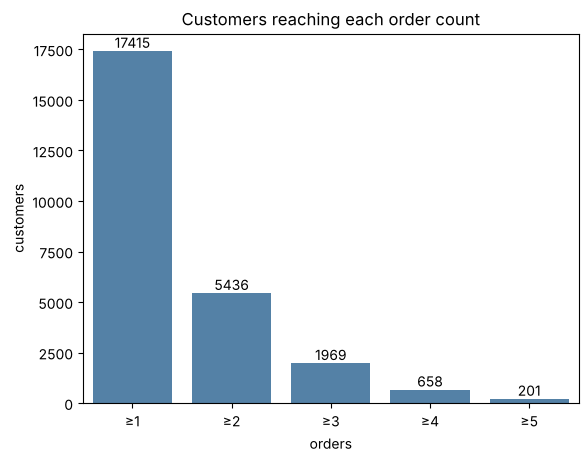

,orders,customers,pct_vs_prev,pct_vs_first
0,≥1,17415,NaN,100.00
1,≥2,5436,31.20,31.20
2,≥3,1969,36.20,11.30
3,≥4,658,33.40,3.80
4,≥5,201,30.50,1.20


In [16]:
reach = orders.groupby('CustomerID')['order_no'].max()
funnel = pd.DataFrame({'orders': ['≥1', '≥2', '≥3', '≥4', '≥5'],
                       'customers': [int((reach >= n).sum()) for n in range(1, 6)]})
funnel['pct_vs_prev'] = (funnel['customers'] / funnel['customers'].shift(1) * 100).round(1)
funnel['pct_vs_first'] = (funnel['customers'] / funnel['customers'].iloc[0] * 100).round(1)

ax = sns.barplot(x='orders', y='customers', data=funnel, color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Customers reaching each order count')
plt.show()
funnel

**OBSERVATIONS:**
- Out of 17,415 customers, 5,436 (31%) placed a 2nd order, 1,969 (11%) a 3rd, 658 (4%) a 4th and 201 (1%) a 5th.
- The conversion rate between steps is fairly even, around 30–36%: 31% (1st to 2nd order), 36% (2nd to 3rd), 33% (3rd to 4th), 31% (4th to 5th).

**INSIGHT:**
- At every step, only about 1 in 3 customers buys again. No step shows an "unusual" drop; retention is steady at each purchase.
- The 1st → 2nd order step has the largest impact in number of customers: 17,415 customers are at this step and 11,979 are lost. Raising this rate by a few percentage points would move more customers to later orders than any other step.
- Note: customers whose first order is close to the end of the data have not had time to buy again, so the 1 → 2 rate is slightly understated. Section 4.2 only includes customers with 12 months of history.

## 4.2. Time to the second order

In [17]:
# Only customers with at least 12 months since their first order, to avoid underestimating the repurchase rate
first2 = (orders[orders['order_no'] <= 2]
          .pivot(index='CustomerID', columns='order_no', values='OrderDate'))
first2['gap'] = (first2[2] - first2[1]).dt.days                       # days from 1st to 2nd order (NaN = no repurchase yet)
mature = first2[first2[1] <= orders['OrderDate'].max() - pd.Timedelta(days=365)].copy()

print(f'Customers with 12+ months of history: {len(mature):,}')
for d in (90, 180, 365):
    print(f'2nd order within {d} days: {(mature["gap"] <= d).mean():.1%}')
mature['gap'].describe(percentiles=[.25, .5, .75])

Customers with 12+ months of history: 12,780
2nd order within 90 days: 4.6%
2nd order within 180 days: 9.0%
2nd order within 365 days: 17.8%


count   4976.00
mean     460.79
std      324.72
min        0.00
25%      195.00
50%      402.00
75%      677.25
max     1451.00
Name: gap, dtype: float64

**OBSERVATIONS:**
- Only customers whose first order was on or before 31/12/2022 (12 months of history) are included: 12,780 customers. Of these, 4,976 (39%) had placed a 2nd order by the end of the data.
- Cumulative rate of placing a 2nd order: 4.6% within 90 days, 9.0% within 180 days, 17.8% within 365 days.
- Among customers who bought again, the median time from the 1st to the 2nd order is 402 days; the middle 50% fall between 195 and 677 days.

**INSIGHT:**
- The repurchase rate rises steadily over time with no clear peak. More than half of repeat purchases happen after more than 1 year (402 days), so customers return slowly and not on a fixed schedule.
- As a result, there is no single "best moment" for a repurchase reminder.

# V. Customer segmentation with RFM

**Scoring (1 to 5 points per customer):**
- **R (Recency):** days from the last purchase to the reference date (last date in the data + 1). Customers are split into 5 equal groups; the more recent the purchase, the higher the score (R = 5 is the 20% of customers who bought most recently).
- **F (Frequency):** number of orders, grouped by actual order count (1, 2, 3, 4, 5+ orders) because frequency is highly skewed.
- **M (Monetary):** total revenue (Sales), split into 5 equal groups. M describes the value of each segment and is not used to assign segments.

**Segment rules** (checked from top to bottom; a customer goes into the first segment whose rule they match):

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R ≥ 4 and F ≥ 3 | Bought recently, 3+ orders |
| Loyal | F ≥ 3 (R ≤ 3) | 3+ orders but not recently |
| Potential Loyalist | R ≥ 4 and F = 2 | Bought recently, 2 orders |
| New Customers | R ≥ 4 and F = 1 | Bought recently, only 1 order |
| At Risk | R ≤ 2 and F ≥ 2 | Not bought for a long time, 2+ orders before |
| About To Sleep | R = 3 and F ≤ 2 | Bought a moderate time ago |
| Lost | R ≤ 2 and F = 1 | Not bought for a long time, only 1 order |

*Only R and F are used to assign segments because frequency is highly skewed (69% of customers placed only 1 order); the standard 3-digit RFM code table would misclassify many customers.*

In [18]:
snapshot = orders['OrderDate'].max() + pd.Timedelta(days=1)             # reference date for Recency
rfm = cust[['CustomerID', 'Frequency', 'Monetary', 'last_order', 'F_score']].copy()
rfm['Recency'] = (snapshot - rfm['last_order']).dt.days

# rank(method='first') so that 5 groups are formed even when many customers share the same value
rfm['R'] = pd.qcut(rfm['Recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = rfm['F_score'].cat.codes + 1
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Assign segments by R and F (F is highly skewed, so the 3-digit RFM code table is not used)
conditions = [(rfm.R >= 4) & (rfm.F >= 3),
              rfm.F >= 3,
              (rfm.R >= 4) & (rfm.F == 2),
              rfm.R >= 4,
              (rfm.R <= 2) & (rfm.F >= 2),
              rfm.R == 3]
names = ['Champions', 'Loyal', 'Potential Loyalist', 'New Customers', 'At Risk', 'About To Sleep']
rfm['Segment_RFM'] = np.select(conditions, names, default='Lost')

seg = (rfm.groupby('Segment_RFM')
          .agg(n_customers=('CustomerID', 'count'), revenue=('Monetary', 'sum'),
               avg_recency=('Recency', 'mean'), avg_orders=('Frequency', 'mean'), avg_spend=('Monetary', 'mean')))
seg['pct_customers'] = (seg['n_customers'] / seg['n_customers'].sum() * 100).round(1)
seg['pct_revenue'] = (seg['revenue'] / seg['revenue'].sum() * 100).round(1)
seg = seg.sort_values('revenue', ascending=False)
seg.round(1)

,n_customers,revenue,avg_recency,avg_orders,avg_spend,pct_customers,pct_revenue
Segment_RFM,,,,,,,
Lost,5929,1486793,953.20,1.00,250.80,34.00,22.80
Champions,1395,1240222,107.80,3.50,889.00,8.00,19.00
About To Sleep,3101,991490,427.70,1.30,319.70,17.80,15.20
Potential Loyalist,1816,937804,127.10,2.00,516.40,10.40,14.40
New Customers,3755,912889,132.70,1.00,243.10,21.60,14.00
Loyal,574,536075,519.40,3.30,933.90,3.30,8.20
At Risk,845,412401,820.40,2.00,488.00,4.90,6.30


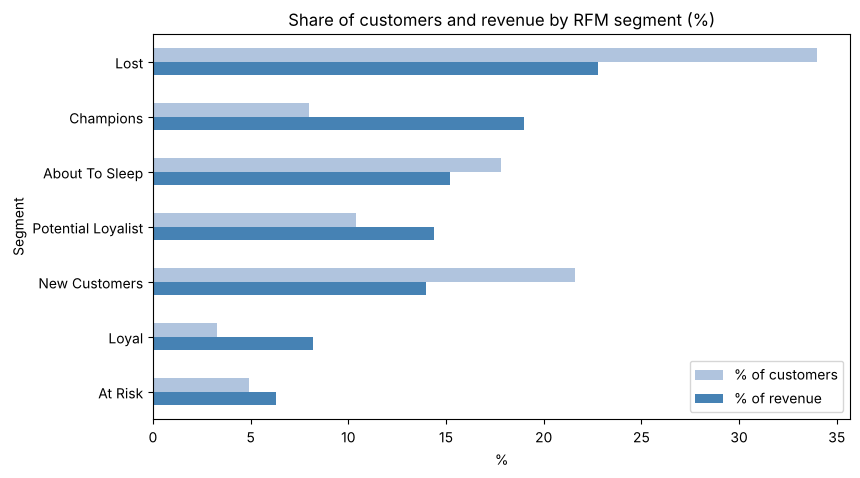

In [19]:
seg[['pct_customers', 'pct_revenue']].plot(kind='barh', figsize=(9, 5), color=['lightsteelblue', 'steelblue'])
plt.title('Share of customers and revenue by RFM segment (%)')
plt.xlabel('%')
plt.ylabel('Segment')
plt.legend(['% of customers', '% of revenue'])
plt.gca().invert_yaxis()
plt.show()

**OBSERVATIONS:**
- The largest segment is Lost (5,929 customers, 34.0%), which is also the largest contributor to revenue (22.8%), but each customer spends only about 251 on average and placed 1 order.
- Champions are only 8.0% of customers but contribute 19.0% of revenue (average spend 889, 3.5 orders, last purchase about 108 days ago). Together with Loyal (3.3% of customers, 8.2% of revenue), these two segments are 11.3% of customers but 27.2% of revenue.
- Loyal customers buy often (3.3 orders) but have not returned for a long time (about 519 days on average), very different from Champions (108 days).
- At Risk and Lost (not bought for a long time) make up 38.9% of customers and 29.1% of revenue.
- New Customers (1 order, bought recently) make up 21.6% of customers; Potential Loyalists (2 orders, bought recently) make up 10.4%.

**INSIGHT:**
- Revenue is concentrated in a small group: about 11% of customers (Champions and Loyal) generate 27% of revenue, so this group needs to be retained.
- New Customers and Potential Loyalists (about 32% of customers) bought recently and are the group with the best chance of moving to a next order.
- Lost is one third of customers but spends little and has not bought for a long time, so it should not receive much investment.

**ACTION SUGGESTIONS (hypotheses, to be tested):**
1. **Champions (1,395 customers):** retain with early-access offers or loyalty points. They already buy regularly, so deep discounts are not needed.
2. **Loyal (574 customers):** they bought often but have not returned for a long time (about 519 days). Send a win-back campaign, since reaching them is cheap and they may respond better than new customers.
3. **New Customers and Potential Loyalists (5,571 customers):** they bought recently; send an offer for the next order. This is the most suitable group for the voucher A/B test in section VII.
4. **At Risk and About To Sleep (3,946 customers):** send reminders or offers before they become Lost.
5. **Lost (5,929 customers):** use only low-cost channels (email) and avoid heavy investment.

# VI. Profile of repeat buyers

## 6.1. Summary by number of orders

,n_customers,n_orders,avg_sales_per_order,avg_profit_per_order,avg_discount,profit_margin_pct
F_score,,,,,,
1 order,11979,11979,248.64,38.75,0.15,15.59
2 orders,3467,6934,254.24,40.25,0.15,15.83
3 orders,1311,3933,255.41,44.76,0.13,17.52
4 orders,457,1828,244.96,46.81,0.12,19.11
5+ orders,201,1065,304.19,56.83,0.12,18.68


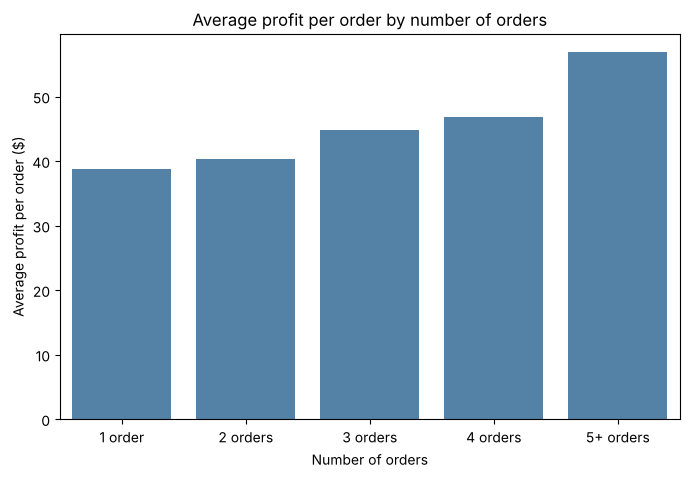

In [20]:
profile = (orders.merge(cust[['CustomerID', 'F_score']], on='CustomerID')
           .groupby('F_score', observed=True)
           .agg(n_customers=('CustomerID', 'nunique'), n_orders=('OrderID', 'count'),
                avg_sales_per_order=('Sales', 'mean'), avg_profit_per_order=('Profit', 'mean'),
                avg_discount=('Discount', 'mean'))
           .assign(profit_margin_pct=lambda d: d['avg_profit_per_order'] / d['avg_sales_per_order'] * 100)
           .round(2))
display(profile)

plt.figure(figsize=(8, 5))
sns.barplot(x=profile.index, y=profile['avg_profit_per_order'], color='steelblue')
plt.title('Average profit per order by number of orders')
plt.xlabel('Number of orders')
plt.ylabel('Average profit per order ($)')
plt.show()

**OBSERVATIONS:**
- Average profit per order rises with the number of orders: 1 order ≈ 38.8; 2 orders ≈ 40.3; 3 orders ≈ 44.8; 4 orders ≈ 46.8; 5+ orders ≈ 56.8.
- Revenue per order is almost flat for the 1–4 order groups (about 245–255); only the 5+ order group is clearly higher (304.2, about 22% higher than the 1-order group).
- The average discount falls as the number of orders rises: 15% (1–2 orders), 13% (3 orders), 12% (4+ orders).
- In the 1–4 order groups, revenue per order is almost flat but profit still rises (profit margin from 15.6% to 19.1%), together with lower discounts. In the 5+ order group, profit is higher because of both larger orders and lower discounts.
- Note: the 5+ order group has only 201 customers (1,065 orders), so conclusions about it should be treated with caution.

**INSIGHT:**
- Repeat buyers do not get larger discounts than one-time buyers (their average discount is lower: 12% vs 15%), so their returns are probably not driven only by discounts. This is an association in the data, not proof of cause; an A/B test (section VII) is needed to know whether offers make customers buy again.

## 6.2. Income by number of orders

     F_score  AnnualIncome
0    1 order      57968.11
1   2 orders      55067.78
2   3 orders      56430.21
3   4 orders      55929.98
4  5+ orders      55323.38


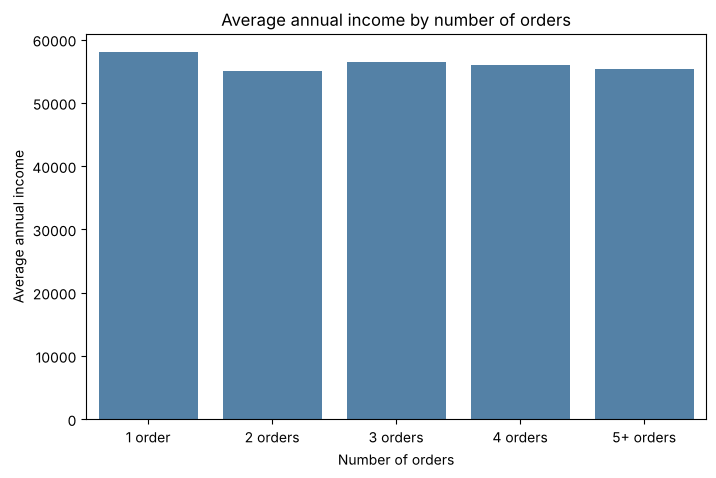

In [21]:
income_by_f = (cust.merge(customers[['CustomerID', 'AnnualIncome']], on='CustomerID', how='left')
                   .groupby('F_score', observed=True)['AnnualIncome'].mean().reset_index())
print(income_by_f)

plt.figure(figsize=(8, 5))
sns.barplot(x='F_score', y='AnnualIncome', data=income_by_f, color='steelblue')
plt.title('Average annual income by number of orders')
plt.xlabel('Number of orders')
plt.ylabel('Average annual income')
plt.show()

**OBSERVATIONS:**
- Average annual income varies only within a narrow range of 55,000–58,000 across all 5 groups and does not rise with the number of orders.
- The 1-order group has the highest income (57,968), about 5% higher than the 5+ order group (55,323). The gap is small, and the 5+ order group has only 201 customers, so it is not enough to draw a conclusion.

**INSIGHT:**
- Income does not help predict who will become a repeat buyer: customers at every income level can come back. Customer care and offers should therefore be targeted by buying behaviour rather than by income.
- The bigger opportunity lies with the majority: 89% of customers place only 1–2 orders, while only about 1% place 5 or more. Moving customers from the 1st to the 2nd order (vouchers, repurchase reminders) has a bigger impact than caring only for the small group of frequent buyers.

## 6.3. Product categories

Category
Body care               142553
Home and Accessories     43058
Hair care                38016
Make up                  36919
Face care                17232
Name: Quantity, dtype: int64


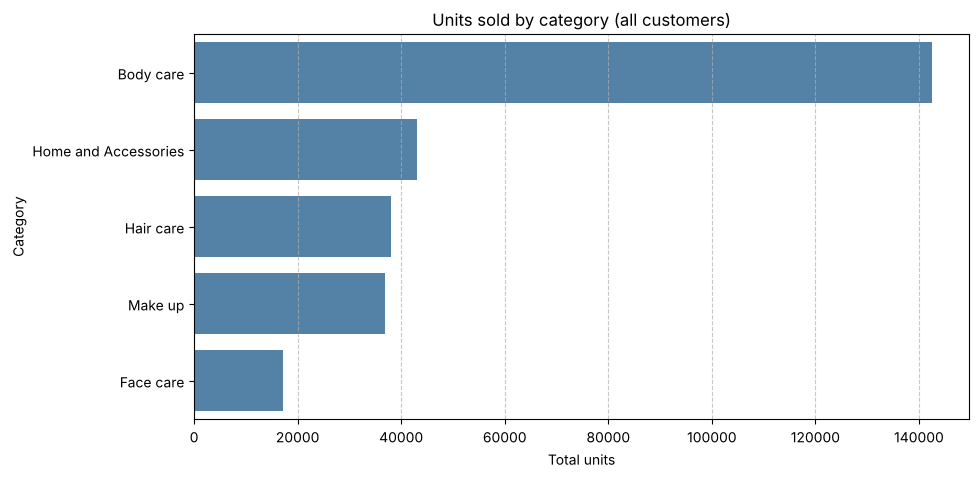

In [22]:
# Units sold by category (all customers)
sold_by_cat = df.groupby('Category')['Quantity'].sum().sort_values(ascending=False)
print(sold_by_cat)

plt.figure(figsize=(10, 5))
sns.barplot(x=sold_by_cat.values, y=sold_by_cat.index, color='steelblue')
plt.title('Units sold by category (all customers)')
plt.xlabel('Total units')
plt.ylabel('Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Category
Body care               64435
Home and Accessories    19536
Hair care               17502
Make up                 17356
Face care                8031
Name: Quantity, dtype: int64


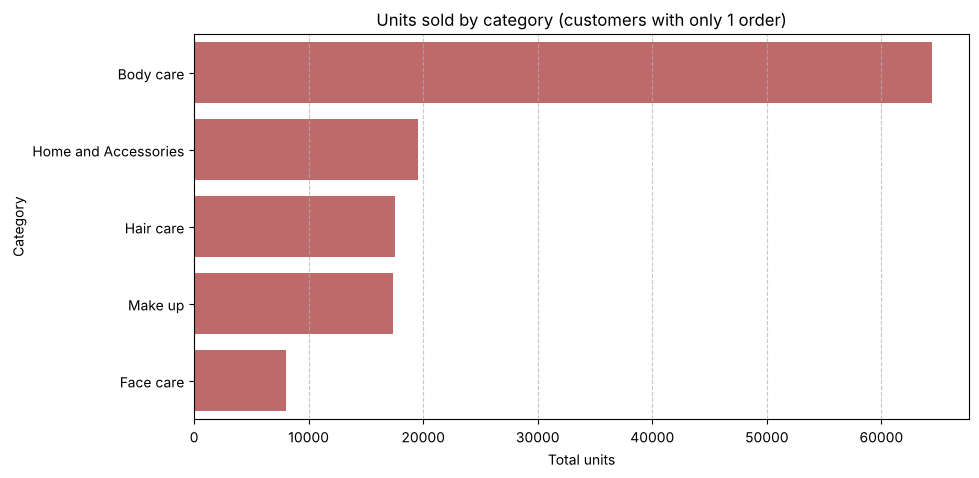

In [23]:
# Units sold by category, customers with only 1 order
one_time_ids = cust.loc[cust['Frequency'] == 1, 'CustomerID']
one_time_cat = (df[df['CustomerID'].isin(one_time_ids)]
                .groupby('Category')['Quantity'].sum().sort_values(ascending=False))
print(one_time_cat)

plt.figure(figsize=(10, 5))
sns.barplot(x=one_time_cat.values, y=one_time_cat.index, color='indianred')
plt.title('Units sold by category (customers with only 1 order)')
plt.xlabel('Total units')
plt.ylabel('Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

**OBSERVATIONS:**
- Body care is the best-selling category with 142,553 units, 51.3% of all units sold and more than 3 times the second category (Home and Accessories, 15.5%). Face care sells the least (6.2%).
- Among customers with only 1 order, the ranking and shares of categories are almost identical to all customers: Body care has 50.8%, and the other categories differ by no more than 0.4 percentage points.
- Customers with only 1 order are about 69% of customers but generate only 45.7% of units sold.

**INSIGHT:**
- Body care is the main volume driver for every customer group. One-time buyers do not buy differently from returning customers, so categories alone cannot tell who will come back.
- This chart measures units, not revenue. Body care sells a lot but may have a low unit price, so its revenue share should be checked before concluding that it is the most valuable category.

Category
Face care              24.30
Make up                21.50
Hair care              21.00
Home and Accessories   20.70
Body care              14.70
Name: CustomerID, dtype: float64


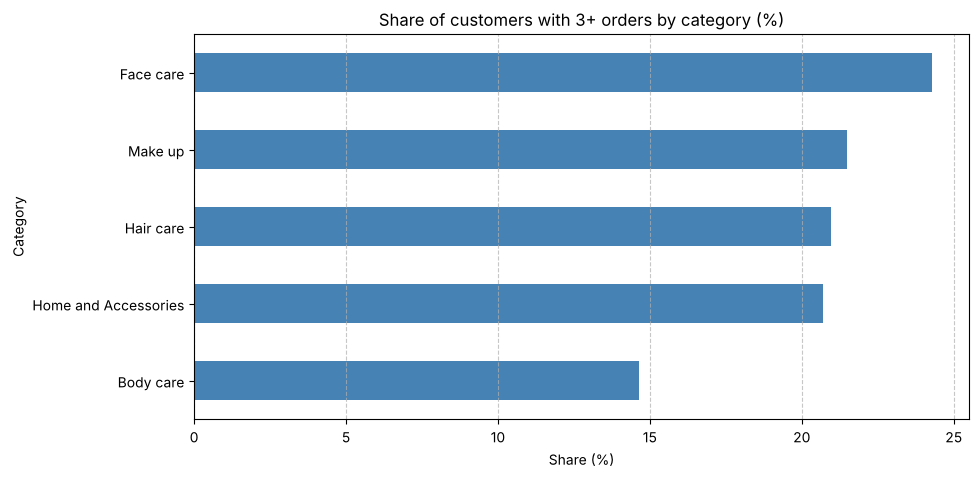

In [24]:
# Share of customers with 3+ orders in each category
loyal_ids = cust.loc[cust['Frequency'] >= 3, 'CustomerID']
customers_by_cat = df.groupby('Category')['CustomerID'].nunique()
loyal_by_cat = df[df['CustomerID'].isin(loyal_ids)].groupby('Category')['CustomerID'].nunique()
loyal_rate = (loyal_by_cat / customers_by_cat * 100).sort_values(ascending=False)
print(loyal_rate.round(1))

plt.figure(figsize=(10, 5))
loyal_rate.plot(kind='barh', color='steelblue')
plt.title('Share of customers with 3+ orders by category (%)')
plt.xlabel('Share (%)')
plt.ylabel('Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.show()

**OBSERVATIONS:**
- Face care has the highest share of customers with 3+ orders (about 24%), slightly above Make up, Hair care and Home and Accessories (about 21%). This suggests that face care buyers tend to come back slightly more often.
- Body care is the lowest (about 15%), clearly below the other categories.
- Note: customers with many orders tend to buy across many categories, so the gaps between the top 4 categories are small and conclusions should be drawn with caution.
- Note: Body care has the most customers, including a large number who bought only once, which pulls its 3+ order share down. Conversely, frequent buyers who shop across categories make up a larger part of small categories such as Face care. The differences between categories therefore reflect each category's customer reach more than its ability to retain customers.

**INSIGHT:**
- Face care may be a trust-based product, so customers rarely switch and keep buying it. This is a hypothesis to be tested.

**ACTION SUGGESTIONS:**
- Try an "upsell from Face care" approach: prioritise face care advertising for new customers, then measure whether the 2nd-order rate increases.
- For Body care buyers, send promotions or usage-guide/review emails to increase the chance of a return.
- Check why Body care is low: if the product simply needs to be repurchased less often, there is no cause for concern; if it is a quality issue, review the supply source.

# VII. A/B test design: second-order voucher

The previous sections only show **associations** in past data, for example repeat buyers receive smaller discounts. To know whether an offer actually **causes** customers to buy again, an experiment with a control group is needed: customers are split **randomly** into two groups, one receives a voucher and the other does not. Because the split is random, the two groups are alike in every other respect, and the difference in repurchase rate can be attributed to the voucher.

The sample dataset contains no experiment, so this section only **designs** the experiment; it has not been run.

**Why the second order:** the funnel in section IV shows that the step from the 1st to the 2nd order loses the most customers in absolute terms (about 69% of customers place only 1 order). Improving this step would have the largest impact.

| Item | Details |
|---|---|
| Hypothesis | Customers who have just placed their first order and receive a voucher have a higher 90-day 2nd-order rate than customers who do not |
| Target group | New customers who have just completed their first order |
| Groups | Random 50/50 split: group A (control, no voucher) and group B (voucher) |
| Primary metric | Share of customers placing a 2nd order within 90 days of the first order |
| Secondary metrics | Profit per 2nd order after the voucher cost, order value |
| Voucher level | Compare 3 options: 5, 10 and 15 USD (explained below) |
| Sample size and duration | Calculated in the code cell below |
| Decision rule | Roll out if group B's rate is higher than group A's with statistical significance (p < 0.05) **and** above the break-even rate of the chosen voucher |

### Method

The design follows 5 steps: (1) measure the current repurchase rate → (2) calculate the rate needed for the voucher to break even at 5, 10 and 15 USD → (3) derive the minimum lift to detect (MDE) → (4) calculate the number of customers needed per group → (5) convert that number into test duration, to choose a feasible voucher level.

**1. Baseline rate (p₀)**

The baseline rate is the repurchase rate **without a voucher**. Among the 12,780 customers with 1 year of history (section 4.2), about **4.6%** placed a 2nd order within 90 days. This is the expected result for group A and the reference point for measuring the lift.

**2. Why 3 voucher levels of 5, 10 and 15 USD**

- The average order value is about 250 USD (section 6.1), so these 3 levels are about **2%, 4% and 6%** of order value, representing a small, medium and large offer.
- The average profit per order is about 40 USD. The voucher must be lower than this; otherwise every order that uses the voucher makes a loss.
- These are assumed levels for comparison. In practice, the business would choose based on its promotion budget.

**3. Break-even rate and MDE**

The voucher is paid to **every** group B customer who places a 2nd order, including those who would have bought anyway. Group B is therefore only more profitable than group A when:

$$p_1 \times (P - V) \ge p_0 \times P \quad\Rightarrow\quad p_1 \ge \frac{p_0 \times P}{P - V}$$

$$MDE = p_1 - p_0$$

Where P is the average profit per order, V is the voucher value and p₁ is group B's break-even rate.

Relative lift = MDE ÷ p₀ × 100: how much the number of repeat buyers must increase, in percent, compared with today.

*Example with 1,000 customers per group, P = 40, V = 10:* group A has 46 repeat buyers (4.6%), earning 46 × 40 = 1,840 USD. In group B, each order earns only 40 − 10 = 30 USD, so 1,840 ÷ 30 ≈ 61 customers are needed, i.e. **6.1%**. MDE = 6.1% − 4.6% = **1.5 percentage points**, a relative lift of about 33%.

**MDE (Minimum Detectable Effect)** is the smallest lift the experiment needs to be able to detect. If the voucher raises the rate by less than the break-even lift, it should not be rolled out even if the lift is detected, so the MDE is set exactly at the break-even lift.

**4. Sample size**

Two parameters follow the standard convention:
- **alpha = 0.05:** accept at most a 5% risk of a "false alarm", i.e. concluding that the voucher works when it does not. After the experiment, the p-value is compared with this threshold.
- **power = 0.8:** if the voucher truly raises the rate by at least the MDE, the experiment has an 80% chance of detecting it. Power is only used to calculate the sample size.

Number of customers needed **per group**:

$$n = \frac{(1.96 + 0.84)^2 \times \big[p_0(1-p_0) + p_1(1-p_1)\big]}{(p_1 - p_0)^2}$$

- **(1.96 + 0.84)²:** the required level of certainty (1.96 for alpha = 0.05; 0.84 for power = 0.8).
- **Numerator:** the natural random variation in the repurchase rate.
- **Denominator:** the squared lift to detect (MDE). The smaller the lift, the more customers are needed: halving the MDE requires about 4 times as many customers.

*Example for the 10 USD voucher:* n = 7.85 × (0.0464 × 0.9536 + 0.0612 × 0.9388) ÷ 0.0148² ≈ **3,640 customers per group** (the code gives 3,641). The `NormalIndPower` function in the code uses an equivalent formula.

**5. Test duration**

$$\text{Duration} = \frac{2 \times n}{\text{new customers per quarter}} + \text{follow-up period}$$

- **2 × n:** total number of customers in both groups.
- **New customers per quarter:** only new customers can join the experiment. On average there are about **1,088 new customers per quarter** (17,415 customers ÷ 16 quarters).
- **Follow-up period:** the last customer to join must be followed for another 90 days (about **1 quarter**) to see whether they place a 2nd order.

*Example for the 10 USD voucher:* 2 × 3,641 ÷ 1,088 ≈ 6.7 quarters to enrol customers, plus 1 quarter of follow-up, about **7.7 quarters (almost 2 years)** in total.

In [25]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

p0 = (mature['gap'] <= 90).mean()              # baseline: 2nd order within 90 days
profit_per_order = orders['Profit'].mean()     # average profit per order
new_per_quarter = cohort_size.mean()           # average new customers per quarter

scenarios = pd.DataFrame({'voucher': [5, 10, 15]})
scenarios['breakeven_rate'] = p0 * profit_per_order / (profit_per_order - scenarios['voucher'])
scenarios['mde'] = scenarios['breakeven_rate'] - p0
scenarios['relative_lift_pct'] = scenarios['mde'] / p0 * 100
scenarios['n_per_group'] = [int(np.ceil(NormalIndPower().solve_power(proportion_effectsize(p1, p0), alpha=0.05, power=0.8, ratio=1)))
                            for p1 in scenarios['breakeven_rate']]
scenarios['quarters_needed'] = 2 * scenarios['n_per_group'] / new_per_quarter
scenarios['total_quarters'] = scenarios['quarters_needed'] + 1   # + 90-day follow-up

print(f'Baseline rate: {p0:.1%} | Avg profit per order: ${profit_per_order:.1f} | Avg new customers per quarter: {new_per_quarter:,.0f}')
display(scenarios.assign(breakeven_rate=scenarios['breakeven_rate'] * 100, mde=scenarios['mde'] * 100)
        .rename(columns={'breakeven_rate': 'breakeven_rate_pct', 'mde': 'mde_pp'}).round(2))

Baseline rate: 4.6% | Avg profit per order: $41.4 | Avg new customers per quarter: 1,088


,voucher,breakeven_rate_pct,mde_pp,relative_lift_pct,n_per_group,quarters_needed,total_quarters
0,5,5.28,0.64,13.74,18187,33.42,34.42
1,10,6.12,1.48,31.85,3641,6.69,7.69
2,15,7.28,2.64,56.83,1250,2.30,3.30


**OBSERVATIONS:**
- The baseline rate is about 4.6% and the average profit per order is about 41.4. The larger the voucher, the higher the rate needed to break even: 5.3% (5 USD), 6.1% (10 USD) and 7.3% (15 USD).
- The 5 USD voucher needs a lift of only 0.6 percentage points but requires 18,187 customers per group, about 34 quarters. This is far too long, so it is not feasible.
- The 15 USD voucher needs only 1,250 customers per group (about 3.3 quarters), but the repurchase rate must rise by 2.6 percentage points (about 57%) to break even.
- The 10 USD voucher sits in between: it needs a lift of 1.5 percentage points (about 32%) and 3,641 customers per group (about 7.7 quarters).
- Note: the results are only meaningful if customers are split randomly and nothing else changes (prices, other promotions) during the test.

**INSIGHT:**
- A small voucher is easy to break even on but hard to measure; a large voucher is easy to measure but hard to make profitable. The voucher level therefore needs to be chosen based on both cost and test duration, not only on the size of the offer.
- With about 1,088 new customers per quarter, only the 15 USD voucher gives a result within 1 year. The low baseline rate (below 5%) and the limited number of new customers are the main constraints when testing on this sample dataset.

**ACTION SUGGESTIONS:**
- Test the 15 USD voucher first because it gives the fastest result (about 10 months). If group B's rate exceeds 7.3%, roll it out; if it beats group A but stays below break-even, test a lower voucher level next.
- Measure profit after the voucher cost, not only the repurchase rate, before a wider rollout.

# VIII. Conclusions, recommendations and data limitations

## 8.1. Key findings
1. **Few customers return:** 69% of customers (11,979) placed only 1 order, and only 31% placed a 2nd. In each quarter, only about 4–8% of a cohort's customers buy again.
2. **The step from the 1st to the 2nd order loses the most customers in absolute terms** (almost 12,000). From the 2nd order on, each step keeps about one third of customers (31–36%).
3. **Customers return slowly:** among customers with 12 months of history, only 4.6% placed a 2nd order within 90 days, 9.0% within 180 days and 17.8% within 365 days. The median time to the 2nd order is 402 days, meaning more than half of repeat buyers came back after more than 1 year.
4. **Segment and income do not separate repeat buyers:** Corporate and Consumer customers return at similar rates; average income is almost the same across order-count groups (55,000–58,000).
5. **Revenue is concentrated in a small group (RFM):** Champions and Loyal are only 11.3% of customers but generate 27.2% of revenue. New Customers and Potential Loyalists (about 32% of customers) bought recently and have the best chance of moving to a next order.
6. **Repeat buyers bring higher profit per order** (about 56.8 vs 38.8) despite receiving smaller discounts (12% vs 15%).
7. **Categories:** Body care accounts for 51.3% of units sold in every customer group. Face care has the highest share of customers with 3+ orders (about 24%, vs about 15% for Body care), but this gap reflects each category's customer reach more than its ability to retain customers.

## 8.2. Recommendations
1. Focus on moving customers from the 1st to the 2nd order with repurchase reminders or vouchers, since this step loses the most customers and customers usually return very slowly.
2. Test offers with an A/B test before a wide rollout (section VII). Start with the 15 USD voucher because it gives the fastest result (about 10 months); roll out only if the repurchase rate exceeds the 7.3% break-even rate.
3. Target offers by buying behaviour (RFM), not by income or Segment: retain Champions, move New Customers and Potential Loyalists to their next order, and use only low-cost campaigns for Lost customers.
4. Try Face care as an introductory product for new customers and measure the 2nd-order rate. This is a hypothesis to be tested.

## 8.3. Data limitations
- The data ends in 2023Q4, so later cohorts have fewer quarters of history; customers who first bought near the end of the data have not had time to return.
- Section VII is a design only, with no real results; a real experiment is needed to verify it.
- There is no information on channels, marketing spend or promotions, so the explanations of seasonal patterns are hypotheses.